## Representación en grafos: Node2Vec

- Se aprenden embeddings de los proveedores con **Node2Vec** sobre el subgrafo de co-participación

- Se elige la dimensión y se precalcula la **grilla de p y q** completa

- **SVD** de la adyacencia normalizada como referencia lineal

- **Local:** numpy (paseos), gensim (Word2Vec) y scikit-learn (SVD)

- **Sin Spark:** el grafo cabe en memoria y MLlib no tiene Node2Vec

### Constantes

- `RANGO_P`, `RANGO_Q`: parámetros de retorno y de entrada-salida de Node2Vec

- `RANGO_DIM`: dimensiones del embedding que se comparan

- `N_PASEOS` = 10, `LARGO` = 40, `VENTANA` = 5, `EPOCAS` = 1

- `K_NN` = 10: vecinos en el embedding con que se perfila cada configuración

- `N_MUESTRA` = 5,000: nodos sobre los que se miden los vecinos

- `SEMILLAS`: semillas para medir la estabilidad

In [1]:
RANGO_P = [0.25, 1.0, 4.0]
RANGO_Q = [0.25, 1.0, 4.0]
RANGO_DIM = [32, 64, 128]
N_PASEOS, LARGO, VENTANA, EPOCAS = 10, 40, 5, 1
K_NN = 10
N_MUESTRA = 5000
SEMILLAS = [42, 7]

### Detalle

| Configuración | Paseo |
|---|---|
| p = 1, q = 1 | Paseo aleatorio ponderado (DeepWalk) |
| q > 1 (q = 4) | Tipo **BFS**: se queda en el vecindario inmediato del nodo previo |
| q < 1 (q = 0.25) | Tipo **DFS**: se aleja y recorre el grupo |
| p chico (0.25) | Vuelve seguido al nodo previo |
| p grande (4) | Evita volver |

### Utilidades

In [2]:
NOTEBOOK = "b_node2vec"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

- `nodos`, `aristas` y `aristas_anio`

- Tipología de KMeans solo para **describir** los vecinos

In [4]:
nodos = pd.read_parquet(datos_dir / "nodos.parquet")
aristas = pd.read_parquet(datos_dir / "aristas.parquet")
aristas_anio = pd.read_parquet(datos_dir / "aristas_anio.parquet")
n = len(nodos)
A = matriz_adyacencia(aristas.i.to_numpy(), aristas.j.to_numpy(), aristas.peso.to_numpy(), n)
tip = tipologia_proveedor(nodos.clave)
rng = np.random.default_rng(SEED)
muestra = np.sort(rng.choice(n, N_MUESTRA, replace=False))
print(f"nodos: {n:,} | aristas: {len(aristas):,} | con tipología: {pd.notna(tip).sum():,}")

nodos: 56,948 | aristas: 1,382,617 | con tipología: 11,662


---
### **1. Costo**

- Un embedding de referencia con p = q = 1 y 64 dimensiones

- Tiempo de los paseos, de Word2Vec y memoria de los paseos

In [5]:
E_ref, t_ref = node2vec(A, 1.0, 1.0, 64, N_PASEOS, LARGO, VENTANA, EPOCAS)
costo = pd.DataFrame([("nodos", n), ("paseos", n * N_PASEOS), ("tokens (nodos visitados)", n * N_PASEOS * LARGO),
                      ("tiempo paseos (s)", t_ref["t_paseos_s"]), ("tiempo Word2Vec (s)", t_ref["t_w2v_s"]),
                      ("memoria de los paseos (MB)", t_ref["mb_paseos"])], columns=["medida", "valor"]).round(1)
costo

,medida,valor
0,nodos,56948.0
1,paseos,569480.0
2,tokens (nodos visitados),22779200.0
3,tiempo paseos (s),20.3
4,tiempo Word2Vec (s),270.6
5,memoria de los paseos (MB),91.1


- **57k nodos × 10 paseos × 40 pasos = 22.8M de tokens** por embedding

- Los paseos vectorizados toman ~19 s

- **Word2Vec es el 93% del costo** (270 s con un hilo, 64 dimensiones)

- 91 MB de paseos en memoria: cabe de sobra en local

---
### **2. Dimensión `DIM`**

- **Criterio sin fuga:** embedding solo con el grafo de **2023**

- Se mide si separa los pares que **aparecen en 2024** de pares al azar

- Puntaje del par = coseno entre los dos embeddings (sin clasificador: solo la geometría del espacio)

- AUC = probabilidad de que un par nuevo real tenga mayor coseno que uno al azar

In [6]:
A23 = grafo_anios(aristas_anio, [2023], n)
act23 = np.flatnonzero(np.diff(A23.indptr) > 0)
pos24 = pares_nuevos(aristas_anio, 2024, A23, act23)
neg24 = negativos(A23, _llave(pos24[:, 0], pos24[:, 1], n), act23, len(pos24), 0.0, rng)
ii, jj = np.r_[pos24[:, 0], neg24[:, 0]], np.r_[pos24[:, 1], neg24[:, 1]]
y = np.r_[np.ones(len(pos24)), np.zeros(len(neg24))]
print(f"grafo 2023: {len(act23):,} nodos activos, {A23.nnz // 2:,} aristas | pares 2024: {len(pos24):,} positivos + {len(neg24):,} al azar")

dimension = []
for d in RANGO_DIM:
    E23, _, t = node2vec_activos(A23, 1.0, 1.0, d, n_paseos=N_PASEOS, largo=LARGO, ventana=VENTANA, epocas=EPOCAS)
    En = normalizar(E23)
    dimension.append({"dim": d, "auc_coseno": roc_auc_score(y, (En[ii] * En[jj]).sum(1)),
                      "tiempo_s": t["t_paseos_s"] + t["t_w2v_s"]})
dimension = pd.DataFrame(dimension).round(4)
dimension

grafo 2023: 30,632 nodos activos, 482,854 aristas | pares 2024: 213,051 positivos + 213,051 al azar


,dim,auc_coseno,tiempo_s
0,32,0.8788,76.4256
1,64,0.8621,144.7067
2,128,0.8530,257.7794


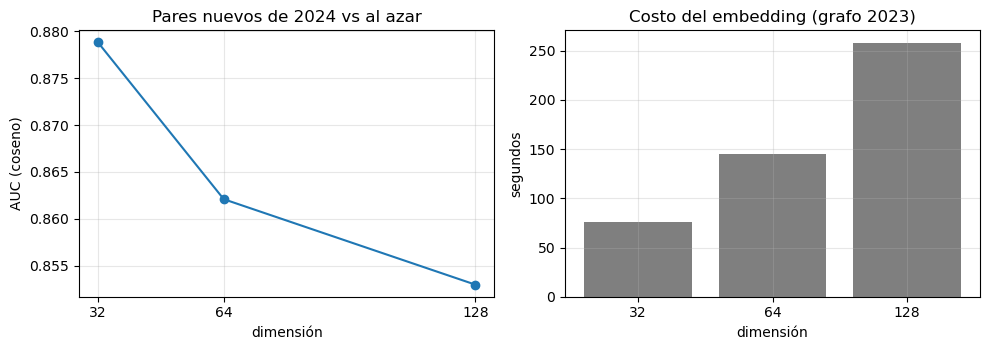

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(dimension.dim, dimension.auc_coseno, "o-")
ax[0].set(xticks=RANGO_DIM, xlabel="dimensión", ylabel="AUC (coseno)", title="Pares nuevos de 2024 vs al azar")
ax[1].bar(dimension.dim.astype(str), dimension.tiempo_s, color="tab:gray")
ax[1].set(xlabel="dimensión", ylabel="segundos", title="Costo del embedding (grafo 2023)")
mostrar_fig("dimension")

- **32 dimensiones dan el mejor AUC (0.879)**, sobre 64 (0.862) y 128 (0.853)

- Con 31k nodos activos y paseos de 40 pasos, más dimensiones sobreajustan el ruido de co-participaciones esporádicas

- Se fija `DIM = 32`: mejor separación de los pares futuros, la mitad de memoria que 64 y la mitad de tiempo

In [8]:
DIM = 32

---
### **3. Grilla p × q**

- Se entrena una vez cada combinación de `RANGO_P` × `RANGO_Q` sobre el subgrafo completo

- Cada embedding se guarda en `temp/datos/emb_p<p>_q<q>.npy`

In [9]:
nombre = lambda p, q: f"p{p:g}_q{q:g}"
grilla, embs = [], {}
for p in RANGO_P:
    for q in RANGO_Q:
        E, t = (E_ref, t_ref) if (p, q, DIM) == (1.0, 1.0, 64) else node2vec(A, p, q, DIM, N_PASEOS, LARGO, VENTANA, EPOCAS)
        embs[nombre(p, q)] = E
        np.save(datos_dir / f"emb_{nombre(p, q)}.npy", E)
        grilla.append({"config": nombre(p, q), "p": p, "q": q, "tiempo_s": round(t["t_paseos_s"] + t["t_w2v_s"], 1)})
grilla = pd.DataFrame(grilla)
grilla

,config,p,q,tiempo_s
0,p0.25_q0.25,0.25,0.25,170.9
1,p0.25_q1,0.25,1.00,202.4
2,p0.25_q4,0.25,4.00,239.3
3,p1_q0.25,1.00,0.25,170.7
4,p1_q1,1.00,1.00,149.7
5,p1_q4,1.00,4.00,154.7
6,p4_q0.25,4.00,0.25,166.6
7,p4_q1,4.00,1.00,149.0
8,p4_q4,4.00,4.00,156.5


#### a. SVD como embedder

Misma dimensión pero sin paseos ni p, q

In [10]:
t0 = time.time()
embs["svd"] = embedding_svd(A, DIM)
np.save(datos_dir / "emb_svd.npy", embs["svd"])
print(f"SVD: {time.time() - t0:.1f} s")

SVD: 2.7 s


---
### **4. Qué captura cada configuración**

- Para cada nodo de la muestra, sus `K_NN` vecinos más cercanos en el embedding

- **Al azar:** lo mismo con vecinos sorteados

In [11]:
NN = {c: vecinos_emb(E, muestra, K_NN) for c, E in embs.items()}
NN["al azar"] = rng.choice(n, (N_MUESTRA, K_NN))
perfil = pd.DataFrame({c: perfil_vecindad(m, muestra, A, nodos, tip) for c, m in NN.items()}).T
perfil.index.name = "config"
perfil.round(3)

,% vecinos en el grafo,% misma región,% misma familia,% mismo segmento,% misma tipología,rol (Spearman grado)
config,,,,,,
p0.25_q0.25,27.238,61.688,53.871,69.416,65.378,0.803
p0.25_q1,27.286,60.202,53.943,69.567,65.490,0.819
p0.25_q4,27.118,59.338,53.998,69.393,65.998,0.822
p1_q0.25,27.098,61.628,53.545,69.213,65.937,0.799
p1_q1,27.282,60.756,53.928,69.563,66.140,0.813
p1_q4,26.920,58.876,54.126,69.581,65.333,0.830
p4_q0.25,27.310,61.650,53.687,69.250,66.259,0.801
p4_q1,27.272,60.770,53.955,69.527,65.608,0.817
p4_q4,26.684,59.384,53.834,69.225,66.627,0.831


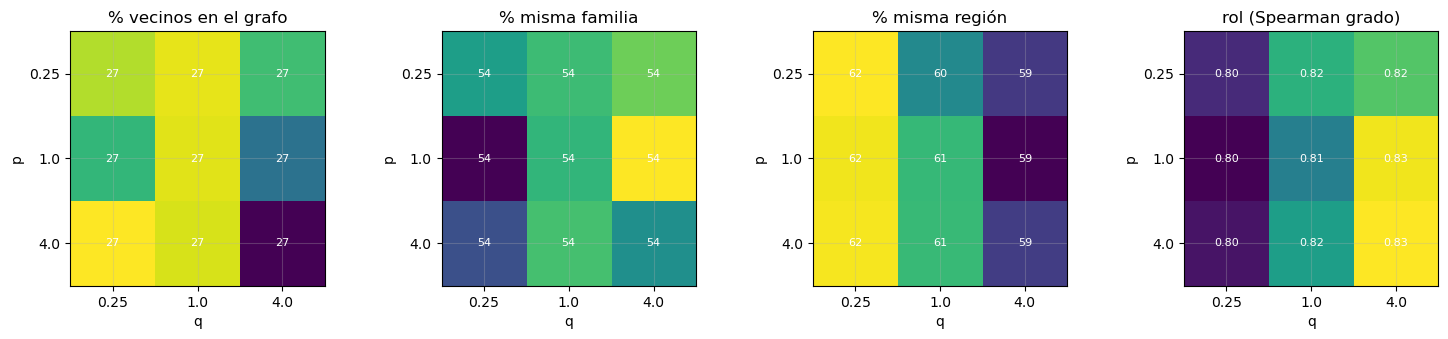

In [12]:
pq_ = perfil.loc[[nombre(p, q) for p in RANGO_P for q in RANGO_Q]]
cols = ["% vecinos en el grafo", "% misma familia", "% misma región", "rol (Spearman grado)"]
fig, ax = plt.subplots(1, len(cols), figsize=(15, 3.4))
for k_, c in enumerate(cols):
    M = pq_[c].to_numpy().reshape(len(RANGO_P), len(RANGO_Q))
    im = ax[k_].imshow(M, cmap="viridis")
    ax[k_].set(xticks=range(len(RANGO_Q)), xticklabels=RANGO_Q, yticks=range(len(RANGO_P)), yticklabels=RANGO_P,
               xlabel="q", ylabel="p", title=c)
    for (r_, s_), val in np.ndenumerate(M):
        ax[k_].text(s_, r_, f"{val:.2f}" if "rol" in c else f"{val:.0f}", ha="center", va="center", color="w", fontsize=8)
mostrar_fig("perfil_pq")

- **Capturan mercado:** ~60% de los vecinos son de la misma región (13% al azar) y 54% de la misma familia UNSPSC

- q = 0.25 (DFS) sube la homofilia regional (61.6-61.7%) y baja el rol (0.80)

- q = 4 (BFS) baja la región (58.9-59.4%) y sube el rol (0.82-0.83): vecinos con un grado parecido

- Cada proceso une a **todos** sus postores en un clique; el vecindario inmediato (BFS) y el mercado (DFS)

- **Rol alto en todas (0.8):** proveedores que ofertan mucho quedan cerca de otros que ofertan mucho

---
### **5. Parecido entre configuraciones y estabilidad**

- **Jaccard de vecinos:** fracción de los `K_NN` vecinos que comparten dos configuraciones

- **Estabilidad:** misma configuración con otra semilla

- Si cambia mucho, los vecinos no son confiables

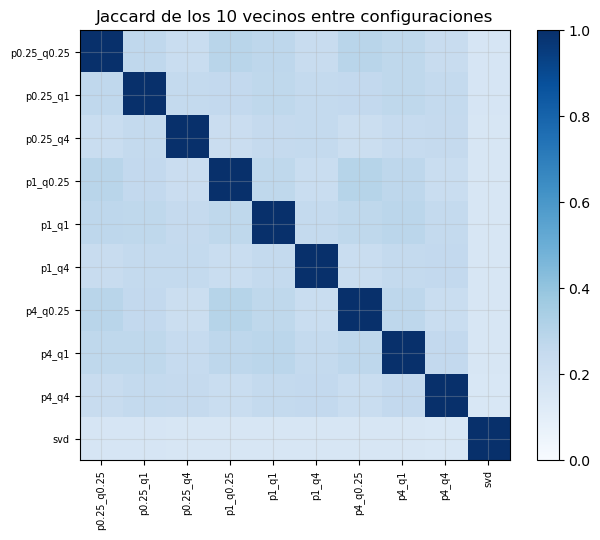

In [13]:
confs = list(embs)
similitud = pd.DataFrame([[jaccard_vecinos(NN[a_], NN[b_]) for b_ in confs] for a_ in confs], index=confs, columns=confs)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(similitud, cmap="Blues", vmin=0, vmax=1)
ax.set(xticks=range(len(confs)), xticklabels=confs, yticks=range(len(confs)), yticklabels=confs,
       title=f"Jaccard de los {K_NN} vecinos entre configuraciones")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=7); plt.setp(ax.get_yticklabels(), fontsize=7)
plt.colorbar(im, ax=ax, fraction=.046)
mostrar_fig("similitud_configs")

In [14]:
E_s2, _ = node2vec(A, 1.0, 1.0, DIM, N_PASEOS, LARGO, VENTANA, EPOCAS, seed=SEMILLAS[1])
estabilidad = pd.DataFrame([
    ("Jaccard vecinos: semilla 42 vs 7 (p=1, q=1)", jaccard_vecinos(NN[nombre(1.0, 1.0)], vecinos_emb(E_s2, muestra, K_NN))),
    ("Jaccard vecinos: Node2Vec (1, 1) vs SVD", similitud.loc[nombre(1.0, 1.0), "svd"]),
    ("Jaccard vecinos: al azar vs Node2Vec (1, 1)", jaccard_vecinos(NN["al azar"], NN[nombre(1.0, 1.0)]))],
    columns=["medida", "valor"]).round(3)
estabilidad

,medida,valor
0,"Jaccard vecinos: semilla 42 vs 7 (p=1, q=1)",0.277
1,"Jaccard vecinos: Node2Vec (1, 1) vs SVD",0.163
2,"Jaccard vecinos: al azar vs Node2Vec (1, 1)",0.000


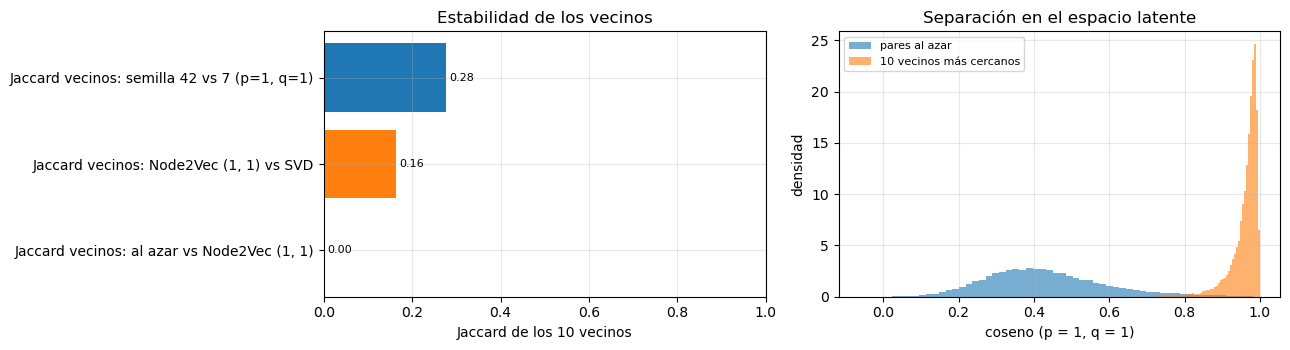

In [15]:
En_ = normalizar(embs[nombre(1.0, 1.0)])
r_ = np.random.default_rng(SEED + 3)
cos_nn = (En_[muestra][:, None, :] * En_[NN[nombre(1.0, 1.0)]]).sum(-1).ravel()
cos_az = (En_[muestra][:, None, :] * En_[r_.integers(0, n, (N_MUESTRA, K_NN))]).sum(-1).ravel()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
ax[0].barh(estabilidad.medida, estabilidad.valor, color=["tab:blue", "tab:orange", "tab:gray"])
ax[0].bar_label(ax[0].containers[0], fmt="%.2f", fontsize=8, padding=2)
ax[0].set(xlim=(0, 1), xlabel=f"Jaccard de los {K_NN} vecinos", title="Estabilidad de los vecinos"); ax[0].invert_yaxis()
ax[1].hist(cos_az, bins=60, alpha=.6, density=True, label="pares al azar")
ax[1].hist(cos_nn, bins=60, alpha=.6, density=True, label=f"{K_NN} vecinos más cercanos")
ax[1].set(xlabel="coseno (p = 1, q = 1)", ylabel="densidad", title="Separación en el espacio latente"); ax[1].legend(fontsize=8)
mostrar_fig("estabilidad")

- **Entre configuraciones:** Jaccard de 0.23-0.30; **entre semillas** de la misma configuración: 0.28

- Cambiar p y q mueve los vecinos **lo mismo que cambiar la semilla**

- Lo estable es el **perfil agregado** (región, familia, rol), no la lista exacta de 10 vecinos

- **Node2Vec vs SVD:** comparten solo 16% de vecinos; el paseo y la factorización ven cosas distintas

- **Separación:** el coseno con los 10 vecinos más cercanos se concentra en 0.90-1.0, y con pares al azar en 0.4

---
### **6. Ejemplo: vecinos de un proveedor**

El proveedor con más procesos de la muestra y sus 5 vecinos en dos configuraciones opuestas

In [16]:
ej = muestra[np.argmax(nodos.n_procesos.to_numpy()[muestra])]
pos_ej = int(np.flatnonzero(muestra == ej)[0])
cols_ej = ["nombre", "region", "familia", "grado", "n_procesos", "n_ganados"]
ejemplo = pd.concat({c: nodos.iloc[NN[c][pos_ej, :5]][cols_ej].reset_index(drop=True)
                     for c in (nombre(0.25, 4.0), nombre(4.0, 0.25))})
print("Proveedor:", nodos.iloc[ej][cols_ej].to_dict())
ejemplo

Proveedor: {'nombre': 'MAYOLDA INVERSIONES S.A.C.', 'region': 'LIMA', 'familia': '7212', 'grado': 2247, 'n_procesos': 3070, 'n_ganados': 12}


nombre  \
p0.25_q4 0                     ARQUITECTURA & CONSTRUCCION RONCAL E.I.R.L.   
         1                                   F&C ACABADOS GENERALES S.A.C.   
         2                        TENER CONSTRUCTORA E INMOBILIARIA S.A.C.   
         3                                        CORPORACION CGP E.I.R.L.   
         4                            INNOVA PROYECTOS & SOLUCIONES S.A.C.   
p4_q0.25 0                        TENER CONSTRUCTORA E INMOBILIARIA S.A.C.   
         1                        EMPRESA CONSTRUCTORA MAHALASAISHA S.A.C.   
         2                     ARQUITECTURA & CONSTRUCCION RONCAL E.I.R.L.   
         3  CONSTRUCTORA ROSA MARIELA-JOAN-CARLOS SOCIEDAD ANONIMA CERRADA   
         4                                                   ENJESA S.A.C.   

                  region familia  grado  n_procesos  n_ganados  
p0.25_q4 0          LIMA    7212     66          82          1  
         1          LIMA    7212     94         129          0  
         2          LIMA    7212     35          34          0  
         3           ICA    7212     12           8          0  
         4      AMAZONAS    7212     20          11          1  
p4_q0.25 0          LIMA    7212     35          34          0  
         1          LIMA    7212     34          12          0  
         2          LIMA    7212     66          82          1  
         3           ICA    7212     12          11          0  
         4  HUANCAVELICA    7212     15          17          1

- El proveedor con más procesos de la muestra es **Mayolda Inversiones**, de **obras (7212) en Lima**: 3,070 procesos y 12 adjudicaciones

- Con BFS (p = 0.25, q = 4) y con DFS (p = 4, q = 0.25), **sus 5 vecinos más cercanos son de obras (7212)**

- La mayoría de Lima, con muchas ofertas y casi ninguna adjudicación

- Las dos configuraciones comparten 2 de 5 vecinos, pero el perfil es el mismo

---
### **7. Escritura de resultados**

In [17]:
config = leer_config()
config.update({"dim": DIM, "rango_p": RANGO_P, "rango_q": RANGO_Q, "n_paseos": N_PASEOS, "largo": LARGO,
               "ventana": VENTANA, "epocas": EPOCAS, "configs": confs})
guardar_config(config)
escritos = guardar_tablas({"costo": costo, "dimension": dimension, "grilla": grilla,
                           "perfil_pq": perfil.reset_index(), "similitud": similitud.reset_index().rename(columns={"index": "config"}),
                           "estabilidad": estabilidad, "ejemplo_vecinos": ejemplo.reset_index(level=0).rename(columns={"level_0": "config"})})

Escrito en 06_Representacion/temp/b_node2vec/: costo, dimension, grilla, perfil_pq, similitud, estabilidad, ejemplo_vecinos


#### a. Verificación

In [18]:
for c in confs:
    E = np.load(datos_dir / f"emb_{c}.npy")
    assert E.shape == (n, DIM) and np.isfinite(E).all() and (np.linalg.norm(E, axis=1) > 0).all(), c
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 4 figuras: dimension, estabilidad, perfil_pq, similitud_configs


---
### **8. Cerrar sesión**

In [19]:
spark.stop()